# 03 - Stage 1 (Basic): Logistic Regression + PCA

The same baseline with one addition: Principal Component Analysis compresses
the 456 correlated features into fewer uncorrelated components before the
classifier sees them. The question this notebook answers is simple - does
reducing dimensionality help a linear model here, or does it throw away
information the classifier needed?

> **Where this fits.** The project is a four-stage progression, every stage
> evaluated the same way so the numbers are directly comparable:
>
> | | Notebook | Stage |
> |---|---|---|
> | 01 | Data and preprocessing | shared by all models |
> | 02 | Logistic Regression | **Stage 1 - Basic** |
> | 03 | Logistic Regression + PCA | **Stage 1 - Basic** |
> | 04 | Random Forest | **Stage 2 - Bagging** |
> | 05 | XGBoost | **Stage 3 - Boosting** |
> | 06 | CNN + LSTM | **Stage 4 - Deep Learning** |
> | 07 | Model comparison | summary |
>
> Run `01` once first - it builds the cache every model notebook loads.

In [1]:
%matplotlib inline
import os, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
np.random.seed(42)

CACHE = "data/epochs.npz"
BLUE, INK, MUTED = "#2a78d6", "#0b0b0b", "#52514e"

## Step 1 - Load the preprocessed epochs

**What this does.** Loads the cache written by notebook `01`: every 2-second EEG
window ("epoch"), its 456 hand-engineered features, the label, and - crucially -
the ID of the subject it came from.

**Why the subject ID matters.** Each person contributes many epochs (61 to 336
of them). If epochs from the same person landed in both training and test sets,
the model could score well by recognising the *person* rather than ADHD - the
label is constant within a subject, so recognising the subject gives the label
away. The subject ID is what lets us prevent that in Step 2.

In [2]:
if not os.path.exists(CACHE):
    raise FileNotFoundError("Run 01_Data_and_Preprocessing.ipynb first - it builds " + CACHE)

cache = np.load(CACHE, allow_pickle=True)
X_feat, y, groups = cache["Xf"], cache["y"].astype(int), cache["g"]

# Band powers span several orders of magnitude and are right-skewed; log1p
# compresses that range so no single feature dominates distance-based or
# gradient-based models. Trees are unaffected either way.
X = np.log1p(np.clip(X_feat, 0, None))
X = np.nan_to_num(X, nan=0.0, posinf=0.0, neginf=0.0)

subj = pd.DataFrame({"ID": groups, "y": y}).groupby("ID").y.first()
print("epochs   :", X.shape[0])
print("features :", X.shape[1])
print("subjects :", len(subj), "  (%d ADHD, %d Control)" % (subj.sum(), (1 - subj).sum()))

epochs   : 16749
features : 456
subjects : 121   (61 ADHD, 60 Control)


## Step 2 - Build subject-grouped cross-validation folds

**What this does.** Splits the 121 subjects into 5 folds. Each fold holds out
about 24 *people*; all of their epochs go to the test side together.
`StratifiedGroupKFold` keeps the ADHD/Control balance similar across folds.

**Why 5 folds and not one split.** With only 121 subjects, which particular
people end up in the test set changes the score a lot. Five folds give five
estimates, and we report their mean and spread. A single split would hide that
spread entirely.

**Why there is an `assert`.** It is cheap insurance: if a future change ever
lets a subject leak across a split, the notebook stops here instead of quietly
reporting an inflated number.

In [3]:
from sklearn.model_selection import StratifiedGroupKFold

N_SPLITS, SEED = 5, 42
cv = list(StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
          .split(X, y, groups))

for k, (tr, te) in enumerate(cv):
    assert not (set(groups[tr]) & set(groups[te])), "subject leaked across split!"
    print("fold %d: train %5d epochs / %2d subjects   test %4d epochs / %2d subjects"
          % (k, len(tr), len(set(groups[tr])), len(te), len(set(groups[te]))))
print("\nVerified: no subject appears on both sides of any fold.")

fold 0: train 13419 epochs / 97 subjects   test 3330 epochs / 24 subjects
fold 1: train 13412 epochs / 97 subjects   test 3337 epochs / 24 subjects
fold 2: train 13342 epochs / 96 subjects   test 3407 epochs / 25 subjects
fold 3: train 13413 epochs / 97 subjects   test 3336 epochs / 24 subjects
fold 4: train 13410 epochs / 97 subjects   test 3339 epochs / 24 subjects

Verified: no subject appears on both sides of any fold.


## Step 3 - Define how a model is scored

**What this does.** Two helpers used by every model notebook.

- `subject_scores` turns epoch-level predictions into one decision per person
  by **averaging that person's epoch probabilities**, then scores those
  decisions. This is the number that matters: diagnosis happens per person, not
  per 2-second window.
- `save_result` writes the 5-fold summary (and each fold's score) to
  `results.csv` / `results_folds.csv`, which notebook `07` reads.

**Why ROC-AUC alongside accuracy.** Accuracy depends on where the 0.5 cut-off
sits; ROC-AUC measures how well the model *ranks* ADHD subjects above controls,
regardless of the cut-off. Both are reported. The standard deviation is the
sample SD across the 5 folds.

In [4]:
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, confusion_matrix, roc_curve

def subject_scores(g_te, y_te, p):
    """Average epoch probabilities per subject, then score the per-subject decision."""
    s = (pd.DataFrame({"ID": g_te, "y": y_te, "p": p})
         .groupby("ID").agg(y=("y", "first"), p=("p", "mean")))
    pred = (s.p > 0.5).astype(int)
    return roc_auc_score(s.y, s.p), accuracy_score(s.y, pred), f1_score(s.y, pred)

def save_result(model, stage, res, path="results.csv"):
    """Upsert one model's summary row; per-fold rows go to results_folds.csv."""
    row = dict(model=model, stage=stage, n_folds=len(res))
    for c in ("epoch_auc", "subject_auc", "subject_acc", "subject_f1"):
        row[c], row[c + "_sd"] = res[c].mean(), res[c].std()
    for p, new in ((path, pd.DataFrame([row])),
                   (path.replace(".csv", "_folds.csv"), res.assign(model=model, stage=stage))):
        try:
            old = pd.read_csv(p); old = old[old.model != model]
            new = pd.concat([old, new], ignore_index=True)
        except FileNotFoundError:
            pass
        new.sort_values(["stage", "model"]).to_csv(p, index=False)
    print("saved %s -> %s" % (model, path))

print("helpers defined")

helpers defined


## Step 4 - Define the model

**What this does.** Standardise, then PCA keeping as many components as needed
to retain 95% of the variance, then logistic regression.

**Why PCA is inside the pipeline.** Exactly as with the scaler: the components
must be learned from training epochs only. Fitting PCA on all the data first
would let the test fold's variance structure shape the components.

**What to expect.** PCA keeps the directions along which features *vary most*
- not the directions that *separate the classes*. Those can coincide, but need
not. Compare the final numbers against `02`.

In [5]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression

model = make_pipeline(
    StandardScaler(),
    PCA(n_components=0.95, random_state=42),
    LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42),
)
model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('pca', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",0.95
,"random_state random_state: int, RandomState instance or None, default=NoneUsed when the 'arpack' or 'randomized' solvers are used. Pass an intfor reproducible results across multiple function calls.See :term:`Glossary <random_state>`... versionadded:: 0.18.0",42
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit co

## Step 5 - Train and evaluate across the 5 folds

**What this does.** For each fold: fit the model on the training subjects'
epochs, predict a probability of ADHD for every test epoch, then score both
per epoch and per subject. Out-of-fold predictions are kept for the plots.

**Why `clone`.** Each fold gets a fresh, unfitted copy of the model so nothing
learned on one fold carries into the next.

In [6]:
from sklearn.base import clone

rows, oof_p, oof_y, oof_g = [], [], [], []
t0 = time.time()
for k, (tr, te) in enumerate(cv):
    m = clone(model)
    m.fit(X[tr], y[tr])
    p = m.predict_proba(X[te])[:, 1]          # P(ADHD) for every test epoch

    ep_auc = roc_auc_score(y[te], p)
    s_auc, s_acc, s_f1 = subject_scores(groups[te], y[te], p)
    rows.append(dict(fold=k, epoch_auc=ep_auc, subject_auc=s_auc,
                     subject_acc=s_acc, subject_f1=s_f1))
    oof_p.append(p); oof_y.append(y[te]); oof_g.append(groups[te])
    print("fold %d  epoch-AUC %.3f | subject-AUC %.3f  subject-acc %.3f"
          % (k, ep_auc, s_auc, s_acc))

res = pd.DataFrame(rows)
oof_p, oof_y, oof_g = map(np.concatenate, (oof_p, oof_y, oof_g))
print("\nLogReg + PCA  -  5-fold results  (%.0f s)" % (time.time() - t0))
for c in ["epoch_auc", "subject_auc", "subject_acc", "subject_f1"]:
    print("  %-12s %.3f +- %.3f" % (c, res[c].mean(), res[c].std()))

save_result("LogReg + PCA", "1 - Basic", res)

fold 0  epoch-AUC 0.630 | subject-AUC 0.743  subject-acc 0.708


fold 1  epoch-AUC 0.715 | subject-AUC 0.875  subject-acc 0.792


fold 2  epoch-AUC 0.749 | subject-AUC 0.859  subject-acc 0.760


fold 3  epoch-AUC 0.596 | subject-AUC 0.590  subject-acc 0.625


fold 4  epoch-AUC 0.645 | subject-AUC 0.660  subject-acc 0.625

LogReg + PCA  -  5-fold results  (6 s)
  epoch_auc    0.667 +- 0.063
  subject_auc  0.745 +- 0.124
  subject_acc  0.702 +- 0.076
  subject_f1   0.730 +- 0.074
saved LogReg + PCA -> results.csv


## Step 6 - One decision per subject

**What this does.** Pools the out-of-fold predictions - every subject was in a
test fold exactly once - and makes the final per-person call by averaging that
person's epoch probabilities.

**Why the pooled numbers differ slightly from the fold means.** The fold means
average five scores each computed on about 24 people; the pooled score is
computed once on all 121. Both are legitimate; the fold mean comes with a
spread, which is why the tables quote it.

In [7]:
subject_pred = (pd.DataFrame({"ID": oof_g, "y_true": oof_y, "p": oof_p})
                .groupby("ID").agg(y_true=("y_true", "first"), p_adhd=("p", "mean")))
subject_pred["pred"] = (subject_pred.p_adhd > 0.5).astype(int)
subject_pred["correct"] = subject_pred.pred == subject_pred.y_true

print("Pooled subject-level performance (n = %d)" % len(subject_pred))
print("  accuracy : %.3f" % accuracy_score(subject_pred.y_true, subject_pred.pred))
print("  ROC-AUC  : %.3f" % roc_auc_score(subject_pred.y_true, subject_pred.p_adhd))
print("  F1       : %.3f" % f1_score(subject_pred.y_true, subject_pred.pred))

wrong = subject_pred[~subject_pred.correct].assign(margin=lambda d: (d.p_adhd - .5).abs())
print("\n%d of %d subjects misclassified. Most confident mistakes:" % (len(wrong), len(subject_pred)))
display(wrong.sort_values("margin", ascending=False).head(5).round(3))

Pooled subject-level performance (n = 121)
  accuracy : 0.702
  ROC-AUC  : 0.738
  F1       : 0.731

36 of 121 subjects misclassified. Most confident mistakes:


,y_true,p_adhd,pred,correct,margin
ID,,,,,
v27p,1,0.006,0,False,0.494
v59p,0,0.933,1,False,0.433
v45p,0,0.930,1,False,0.430
v51p,0,0.823,1,False,0.323
v54p,0,0.805,1,False,0.305


## Step 7 - Confusion matrix and ROC curve

**How to read them.** Left column: every 2-second epoch scored on its own.
Right column: one decision per subject. The subject-level matrix has 121 cells
in total - the top-right cell is controls flagged as ADHD, the bottom-left is
ADHD subjects missed. The ROC curve plots sensitivity against false-alarm rate
at every possible cut-off; the area under it is the ROC-AUC quoted above.

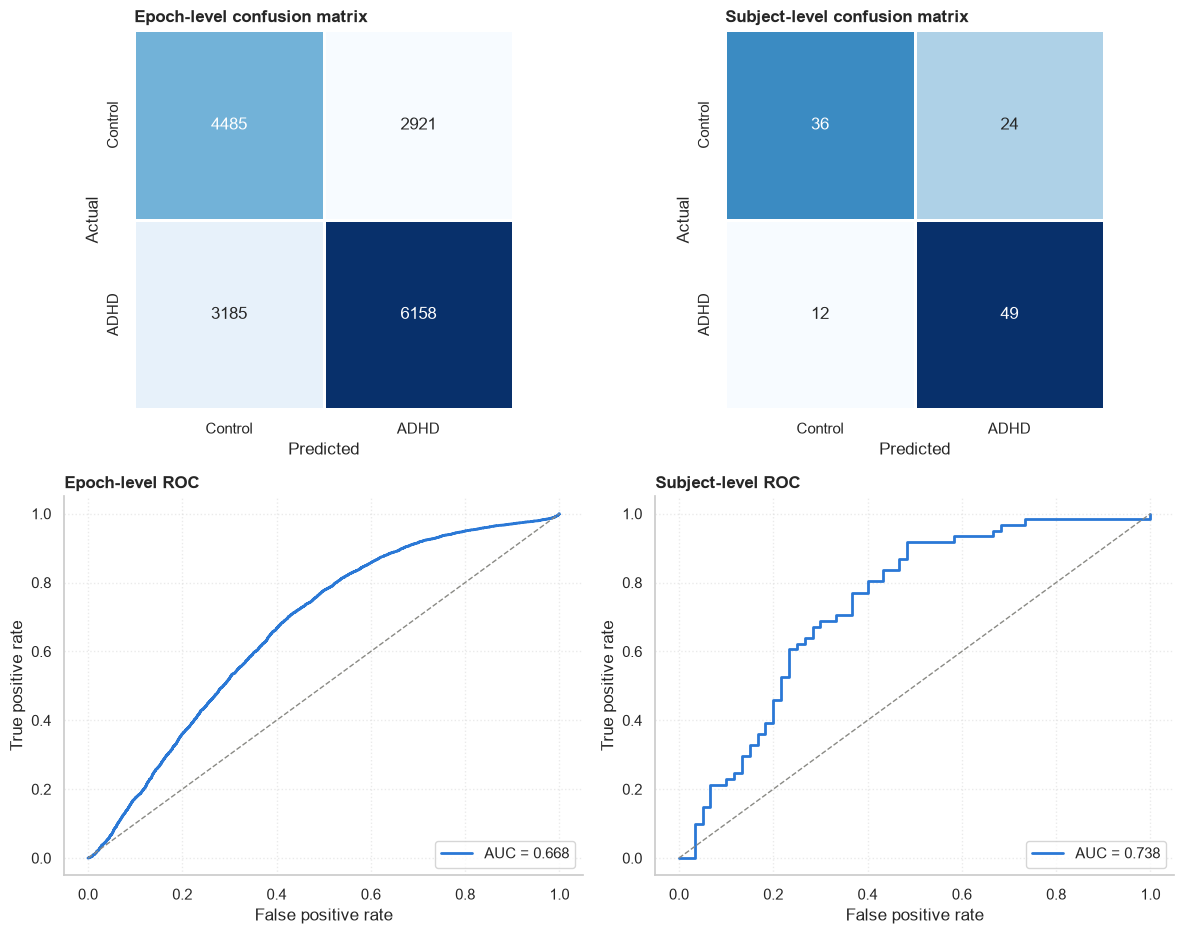

In [8]:
fig, ax = plt.subplots(2, 2, figsize=(12, 9.5))
levels = [(oof_y, oof_p, "Epoch"),
          (subject_pred.y_true.values, subject_pred.p_adhd.values, "Subject")]

for col, (yy, pp, lvl) in enumerate(levels):
    cm = confusion_matrix(yy, (pp > 0.5).astype(int))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, square=True,
                linewidths=1, linecolor="white", ax=ax[0, col],
                xticklabels=["Control", "ADHD"], yticklabels=["Control", "ADHD"])
    ax[0, col].set_title("%s-level confusion matrix" % lvl, weight="bold", loc="left")
    ax[0, col].set_xlabel("Predicted"); ax[0, col].set_ylabel("Actual")

    fpr, tpr, _ = roc_curve(yy, pp)
    ax[1, col].plot(fpr, tpr, lw=2, color=BLUE, label="AUC = %.3f" % roc_auc_score(yy, pp))
    ax[1, col].plot([0, 1], [0, 1], "--", color="#8a8a85", lw=1)
    ax[1, col].set_title("%s-level ROC" % lvl, weight="bold", loc="left")
    ax[1, col].set_xlabel("False positive rate"); ax[1, col].set_ylabel("True positive rate")
    ax[1, col].legend(loc="lower right"); ax[1, col].grid(alpha=.4, ls=":")
    for sp in ("top", "right"): ax[1, col].spines[sp].set_visible(False)

plt.tight_layout(); plt.show()

## Step 8 - How many components, and what did they keep?

**What this does.** Plots cumulative explained variance against the number of
components (a *scree plot*). The dashed line is the 95% threshold used above.

**How to read it.** A steep start means the features are highly redundant -
a handful of components already capture most of the variance. That redundancy
is expected: neighbouring electrodes record overlapping activity, and absolute
and relative band powers are arithmetically related.

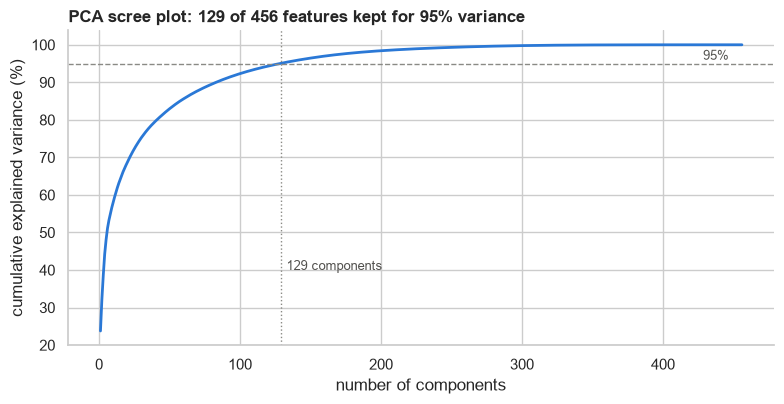

In [9]:
from sklearn.preprocessing import StandardScaler as _SS
from sklearn.decomposition import PCA as _PCA

n_comp = clone(model).fit(X, y)[1].n_components_
cum = np.cumsum(_PCA(random_state=42).fit(_SS().fit_transform(X)).explained_variance_ratio_) * 100

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(range(1, len(cum) + 1), cum, color=BLUE, lw=2)
ax.axhline(95, ls="--", lw=1, color="#8a8a85"); ax.text(len(cum) * .98, 96, "95%", ha="right", fontsize=9, color=MUTED)
ax.axvline(n_comp, ls=":", lw=1, color="#8a8a85"); ax.text(n_comp + 4, 40, "%d components" % n_comp, fontsize=9, color=MUTED)
ax.set_xlabel("number of components"); ax.set_ylabel("cumulative explained variance (%)")
ax.set_title("PCA scree plot: %d of 456 features kept for 95%% variance" % n_comp, weight="bold", loc="left")
for sp in ("top", "right"): ax.spines[sp].set_visible(False)
plt.tight_layout(); plt.show()

## Step 9 - How much the score moves from fold to fold

**Why this plot is here.** It is the honest picture of uncertainty. Each pair
of bars is one fold - one particular set of ~24 test subjects. The gap between
the best and worst fold is what a single train/test split would have hidden:
the same model, the same code, and a score that depends on which people were
held out.

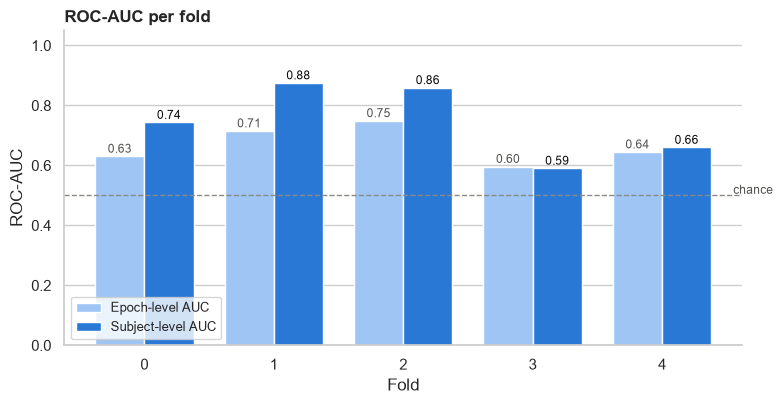

subject-AUC: best fold 0.875, worst fold 0.590, spread 0.285


In [10]:
fig, ax = plt.subplots(figsize=(8, 4.2))
w = .38
ax.bar(res.fold - w/2, res.epoch_auc, w, color="#9ec5f4", label="Epoch-level AUC")
ax.bar(res.fold + w/2, res.subject_auc, w, color=BLUE, label="Subject-level AUC")
for f, e, s in zip(res.fold, res.epoch_auc, res.subject_auc):
    ax.text(f - w/2, e + .012, "%.2f" % e, ha="center", fontsize=8.5, color=MUTED)
    ax.text(f + w/2, s + .012, "%.2f" % s, ha="center", fontsize=8.5, color=INK)
ax.axhline(.5, ls="--", lw=1, color="#8a8a85"); ax.text(4.55, .505, "chance", fontsize=8.5, color=MUTED)
ax.set_ylim(0, 1.05); ax.set_xticks(res.fold); ax.set_xlabel("Fold"); ax.set_ylabel("ROC-AUC")
ax.set_title("ROC-AUC per fold", weight="bold", loc="left")
ax.legend(loc="lower left", fontsize=9); ax.grid(axis="x", visible=False)
for sp in ("top", "right"): ax.spines[sp].set_visible(False)
plt.tight_layout(); plt.show()

print("subject-AUC: best fold %.3f, worst fold %.3f, spread %.3f"
      % (res.subject_auc.max(), res.subject_auc.min(), res.subject_auc.max() - res.subject_auc.min()))

## How to report this

- Quote the **subject-level** figures **with their +- SD**. With ~24 subjects
  per test fold, one person is worth about 4 percentage points of accuracy, so
  the spread is part of the result.
- Compare against the other stages in `07_Model_Comparison.ipynb`. A model
  whose mean is higher by less than one standard deviation has **not** been
  shown to be better on this data.
- **On PCA specifically:** if this notebook's subject-AUC is lower than `02`'s,
  PCA discarded class-relevant information along with the redundancy. That is a
  legitimate finding - "dimensionality reduction did not help" - not a failure.